In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from sklearn.cluster import KMeans

# Simulacion

In [ ]:
N = 50       #Número de neuronas
T = 10000    #Tiempo
p = 0.5      #Probabilidad de conexión.
mu = 0.1     #Probabilidad base de disparo
lmbda = 0.5  #Factor de decaimiento / inercia

# Supuesto: conocemos P_+ y P_
# Mitad activadoras, mitad inhibidoras
P_plus_true = np.arange(0, N // 2)
P_minus_true = np.arange(N // 2, N)

# Matriz de adyacencia (Usando una bernoulli se decide si neurona i está conectada con neurona j)
np.random.seed(42)
theta = np.random.binomial(1, p, size=(N, N))


burn = 0 # Si es 0 estamos en una condicion inicial aleatoria, si es distinto de 0, estacionaria.
X = np.zeros((T+burn, N), dtype=int)
X[0] = np.random.binomial(1, 0.5, size=N) # Condición inicial aleatoria

for t in range(T + burn - 1):
    X_curr = X[t]

    # Separar aportes de neuronas excitadoras e inhibidoras
    # multiplicación matricial para actualizar estado de cada neurona en un mismo tiempo t
    sum_plus = theta[:, P_plus_true] @ X_curr[P_plus_true] #cuenta la cantidad de neuronas de región excitadora que están activas
    sum_minus = theta[:, P_minus_true] @ (1 - X_curr[P_minus_true]) #cuantas inhibidoras están apagadas

    # Calcular probabilidad de activación para el tiempo t+1
    # DEPENDE DEL ESTADO T
    q = mu + (1 - lmbda) * (sum_plus + sum_minus) / N #ecuación 1, probabilidad de transición

    # Simular nuevo estado
    X[t + 1] = np.random.binomial(1, q) #ecuación 13 de paper

X = X[burn:]

# Animación GIF

In [ ]:
#gif se demora harto y en colab crashea el código
#ideal simular en vscode
#inicio IA
import networkx as nx
fig, ax = plt.subplots(figsize=(10, 8))
ax.axis('off')

# grafo
G = nx.from_numpy_array(theta, create_using=nx.DiGraph)
pos = nx.spring_layout(G, seed=42)

# Colores nodos Amarillo=Activa (1), Azul=Inactiva (0)
def get_node_colors(estado):
    return ['#FFD700' if val == 1 else '#2F4F4F' for val in estado]

nodos = nx.draw_networkx_nodes(G, pos, ax=ax,
                               node_color=get_node_colors(X[0]),
                               node_size=150, edgecolors='black')

title = ax.set_title(f"Dinámica de la Red ({N} neuronas) - Tiempo: 0")

def update(frame):

    nodos.set_facecolor(get_node_colors(X[frame]))


    title.set_text(f"Dinámica de la Red ({N} neuronas condición inicial aleatoria, p={p}, mu={mu}, lambda={lmbda})\nTiempo: {frame}")
    return nodos, title

ani = FuncAnimation(fig, update, frames=T, interval=200, blit=True)

nombre_archivo = f'red_neuronal_condicion_aleatoria_con_N{N}_T{T}.gif'
ani.save(nombre_archivo, writer='pillow')
print(f"Simulación finalizada. Animación guardada como '{nombre_archivo}'.")
#fin IA

# Reconstruccion

Tasa de error: 0.0


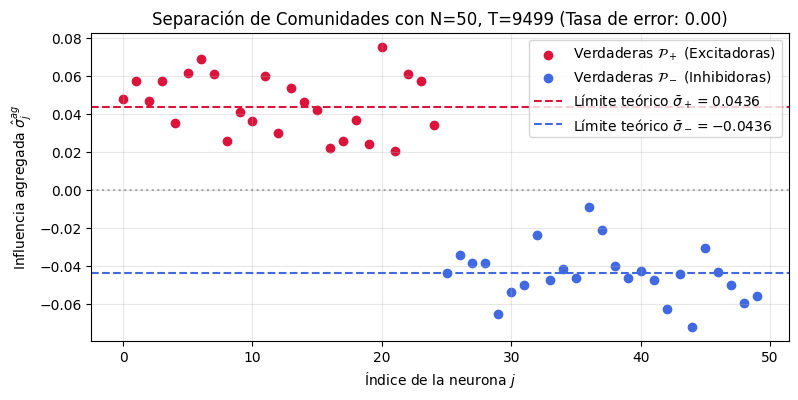

In [ ]:
# Olvidamos ahora P_+ y P_-
# Partimos de un estado estacionario obtenido de la simulacion
# Buscamos ver si se puede inferir las regiones acitvadoras e inhibidoras

# Partimos de un estado estacionario
burn = 500
Xo = X[burn:]
Tn = Xo.shape[0] - 1 #  = 9499

# Estimador de la media:  m_hat = (1/T) sum_t X_t
# taza promedio de disparo (mandar señal)
m_hat = Xo[:Tn].mean(axis=0)

# Estimador de la covarianza con rezago 1:
#entrada (i, j) mide cuanto influye neurona j disparando en el tiempo t (Xo[:Tn]) en la predicción del disparo de la neurona i
# en t+1 (Xo[1:Tn+1]).
Sigma1_hat = (Xo[1:Tn+1] - m_hat).T @ (Xo[:Tn] - m_hat) / Tn

# Vector agregado: sumar cada columna (sobre las filas i)
# si neurona j es excitadora y si dispara en tiempo t, promueve que sus vecinos disparen en tiempo t+1, por lo que el valor del
# vector agregado en j es positivo
# vice versa si neurona i es inhibidor
sigma_hat = Sigma1_hat.sum(axis=0)          # un número por neurona j

# k-means con 2 grupos sobre los N valores de sigma_hat #probar con mas de dos grupos
km = KMeans(n_clusters=2, n_init=10, random_state=0).fit(sigma_hat.reshape(-1, 1))

# El grupo con mayor centro es P_+
plus_label = np.argmax(km.cluster_centers_.ravel())
P_plus_est  = np.where(km.labels_ == plus_label)[0]
P_minus_est = np.where(km.labels_ != plus_label)[0]

# Comparación
# Notar que como T= 9499 y N = 50, N ^2 = 2500 << T y por paper estamos en zona de estimación exacta, figura 1
est_plus  = np.isin(np.arange(N), P_plus_est)
true_plus = np.isin(np.arange(N), P_plus_true)
#misclassification rule teorema 2.9 del paper
print("Tasa de error:", np.mean(est_plus != true_plus))


r_plus, r_minus = len(P_plus_true) / N, len(P_minus_true) / N #proporcion de neuronas activadores e inhibidoras de la cadena real
D_theo = (1 - lmbda) * p * (r_plus - r_minus) #ecuacion 15
m_theo = (mu + (1 - lmbda) * p * r_minus) / (1 - D_theo) #ecuación 15
c1_theo = (1 - lmbda) * m_theo * (1 - m_theo) #ec 16
c2_theo = (((1 - lmbda) ** 2) * (p ** 2) * (r_plus - r_minus) / (1 - D_theo ** 2)) * c1_theo #ec 16, en el caso que #r+=r-, esto c2 =0

sigma_plus_theo = c2_theo + c1_theo * p
sigma_minus_theo = c2_theo - c1_theo * p
#inicio IA
plt.figure(figsize=(9, 4))
plt.scatter(P_plus_true, sigma_hat[P_plus_true], color='crimson', label=r'Verdaderas $\mathcal{P}_+$ (Excitadoras)')
plt.scatter(P_minus_true, sigma_hat[P_minus_true], color='royalblue', label=r'Verdaderas $\mathcal{P}_-$ (Inhibidoras)')
plt.axhline(sigma_plus_theo, color='crimson', linestyle='--', label=f'Límite teórico $\\bar{{\\sigma}}_+ = {sigma_plus_theo:.4f}$')
plt.axhline(sigma_minus_theo, color='royalblue', linestyle='--', label=f'Límite teórico $\\bar{{\\sigma}}_- = {sigma_minus_theo:.4f}$')
plt.axhline(0, color='black', alpha=0.3, linestyle=':')
plt.xlabel('Índice de la neurona $j$')
plt.ylabel(r'Influencia agregada $\hat{\sigma}^{ag}_j$')
plt.title(f'Separación de Comunidades con N={N}, T={Tn} (Tasa de error: {np.mean(est_plus != true_plus):.2f})')
plt.legend()
plt.grid(alpha=0.3)
plt.show()
#Fin IA

Es natural preguntarse por que la tasa de error es 0. Esto esta respladado por el paper. Cuando N es mucho más chico que T, la tasa de error es 0. Se evidencia que al achicar T, la tasa de error aumenta significativamente:

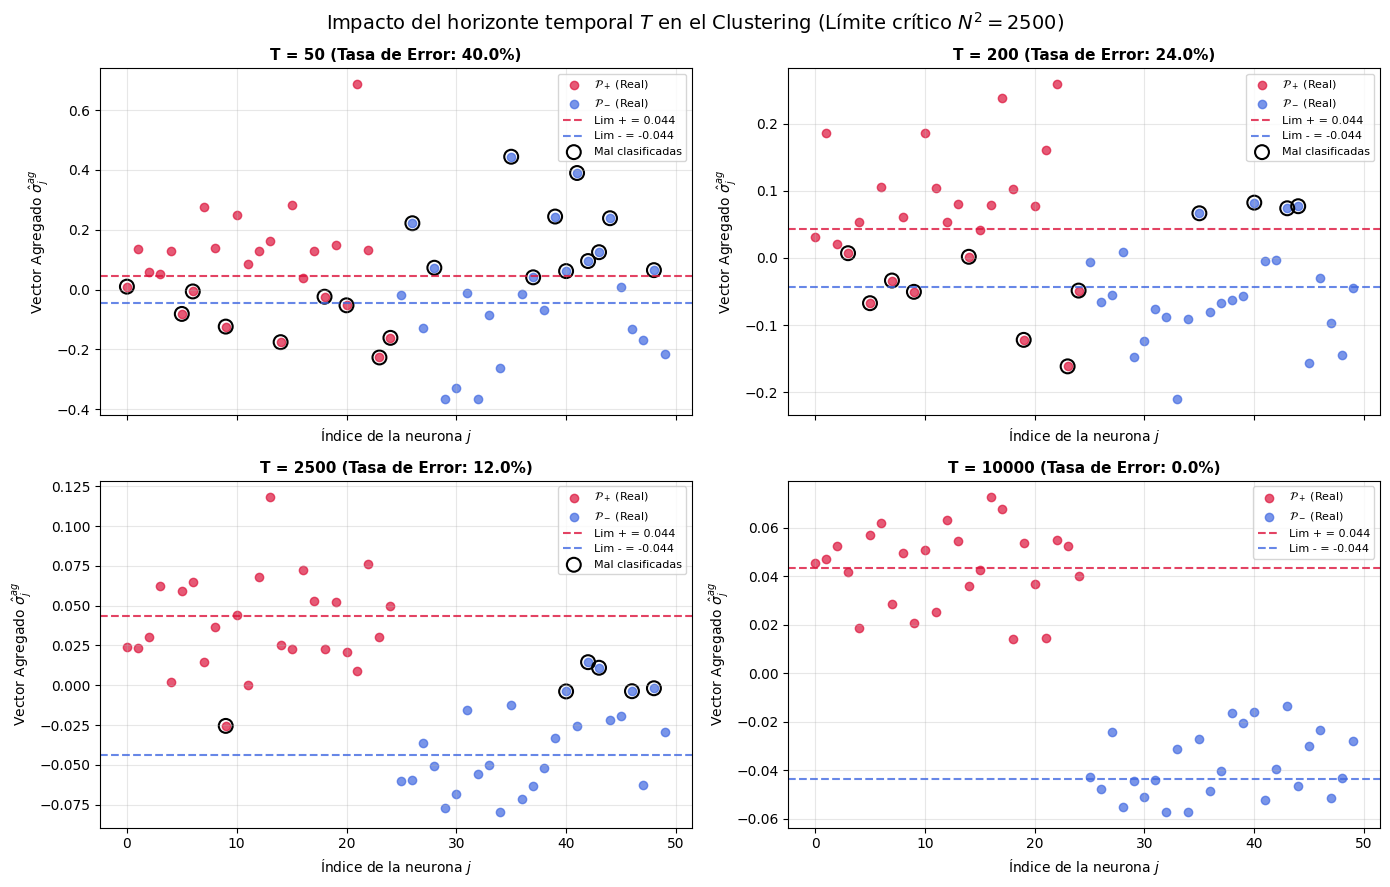

In [ ]:
# hacemos lo mismo que bloque anterior, pero generalizado

def simular_y_graficar_dependencia_T(N, T, p, mu, lmbda, ax=None):

    P_plus_true = np.arange(0, N // 2)
    P_minus_true = np.arange(N // 2, N)


    rng = np.random.default_rng(42)
    theta = rng.binomial(1, p, size=(N, N))

    burn = 500
    X = np.zeros((T + burn + 1, N), dtype=int)
    X[0] = rng.binomial(1, 0.5, size=N)

    for t in range(T + burn):
        s_plus = theta[:, P_plus_true] @ X[t, P_plus_true]
        s_minus = theta[:, P_minus_true] @ (1 - X[t, P_minus_true])
        q = mu + (1 - lmbda) * (s_plus + s_minus) / N
        X[t + 1] = rng.binomial(1, q)

    Xo = X[burn:]


    m_hat = Xo[:T].mean(axis=0)
    Sigma1_hat = (Xo[1:T+1] - m_hat).T @ (Xo[:T] - m_hat) / T
    sigma_hat = Sigma1_hat.sum(axis=0)


    km = KMeans(n_clusters=2, n_init=10, random_state=0).fit(sigma_hat.reshape(-1, 1))
    plus_label = np.argmax(km.cluster_centers_.ravel())
    P_plus_est = np.where(km.labels_ == plus_label)[0]

    est_plus = np.isin(np.arange(N), P_plus_est)
    true_plus = np.isin(np.arange(N), P_plus_true)
    tasa_error = np.mean(est_plus != true_plus)


    r_plus, r_minus = len(P_plus_true) / N, len(P_minus_true) / N
    D_theo = (1 - lmbda) * p * (r_plus - r_minus)
    m_theo = (mu + (1 - lmbda) * p * r_minus) / (1 - D_theo)
    c1_theo = (1 - lmbda) * m_theo * (1 - m_theo)

    if D_theo == 0:
        c2_theo = 0.0
    else:
        c2_theo = (((1 - lmbda) ** 2) * (p ** 2) * (r_plus - r_minus) / (1 - D_theo ** 2)) * c1_theo

    sigma_plus_theo = c2_theo + c1_theo * p
    sigma_minus_theo = c2_theo - c1_theo * p

    #incio IA
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 4))

    ax.scatter(P_plus_true, sigma_hat[P_plus_true], color='crimson', alpha=0.7, label=r'$\mathcal{P}_+$ (Real)')
    ax.scatter(P_minus_true, sigma_hat[P_minus_true], color='royalblue', alpha=0.7, label=r'$\mathcal{P}_-$ (Real)')
    ax.axhline(sigma_plus_theo, color='crimson', linestyle='--', alpha=0.8, label=f'Lim + = {sigma_plus_theo:.3f}')
    ax.axhline(sigma_minus_theo, color='royalblue', linestyle='--', alpha=0.8, label=f'Lim - = {sigma_minus_theo:.3f}')

    # Resaltar neuronas mal clasificadas por K-Means con un círculo a partir del error
    errores = (est_plus != true_plus)
    if np.any(errores):
        ax.scatter(np.where(errores)[0], sigma_hat[errores], facecolors='none', edgecolors='black',
                   s=100, linewidth=1.5, label=f'Mal clasificadas')

    ax.set_title(f'T = {T} (Tasa de Error: {tasa_error:.1%})', fontsize=11, fontweight='bold')
    ax.set_xlabel('Índice de la neurona $j$')
    ax.set_ylabel(r'Vector Agregado $\hat{\sigma}^{ag}_j$')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc='best')

    return tasa_error


N_fijo = 50
p_val, mu_val, lmbda_val = 0.5, 0.1, 0.5

T_valores = [50, 200, 2500, 10000]

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
axes = axes.ravel()

for idx, T_test in enumerate(T_valores):
    simular_y_graficar_dependencia_T(N=N_fijo, T=T_test, p=p_val, mu=mu_val, lmbda=lmbda_val, ax=axes[idx])

plt.suptitle(f'Impacto del horizonte temporal $T$ en el Clustering (Límite crítico $N^2 = {N_fijo**2}$)', fontsize=14)
plt.tight_layout()
plt.show()
#Fin IA

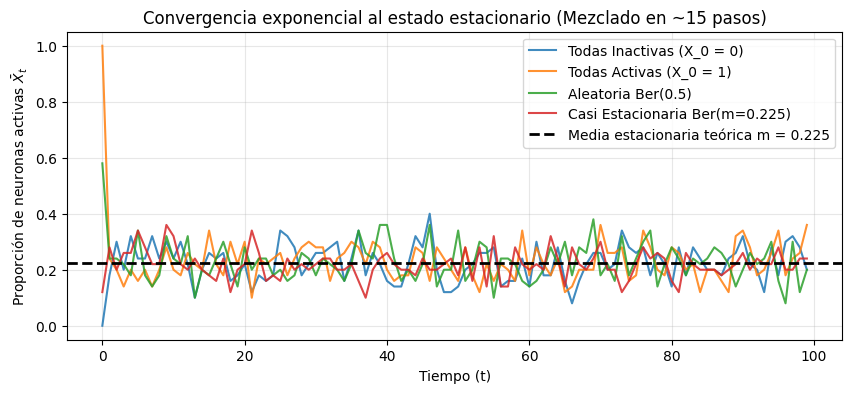

In [ ]:
# condicional aleatoria versus estacionaria
T_short = 100
condiciones = {
    "Todas Inactivas (X_0 = 0)": np.zeros(N, dtype=int),
    "Todas Activas (X_0 = 1)": np.ones(N, dtype=int),
    "Aleatoria Ber(0.5)": np.random.binomial(1, 0.5, size=N),
    f"Casi Estacionaria Ber(m={m_theo:.3f})": np.random.binomial(1, m_theo, size=N)
}
#inicio IA
plt.figure(figsize=(10, 4))
for nombre, x0 in condiciones.items():
    X_temp = np.zeros((T_short, N), dtype=int)
    X_temp[0] = x0
    for t in range(T_short - 1):
        sum_p = theta[:, P_plus_true] @ X_temp[t, P_plus_true]
        sum_m = theta[:, P_minus_true] @ (1 - X_temp[t, P_minus_true])
        q = mu + (1 - lmbda) * (sum_p + sum_m) / N
        X_temp[t + 1] = np.random.binomial(1, q)

    plt.plot(X_temp.mean(axis=1), label=nombre, alpha=0.85)

plt.axhline(m_theo, color='black', linestyle='--', linewidth=2, label=f'Media estacionaria teórica m = {m_theo:.3f}')
plt.xlabel('Tiempo (t)')
plt.ylabel('Proporción de neuronas activas $\\bar{X}_t$')
plt.title('Convergencia exponencial al estado estacionario (Mezclado en ~15 pasos)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()
#fun IA
#no importa el estado inicial del espacio sináptico, con el tiempo se estabiliza y oscila alrededor de la media teórica
## respaldado por paper

# Mapa de calor de matriz de covarianza 0-lagged, 1-lagged de resultados empíricos y comparación con matriz de covarianza 0-lagged teórico

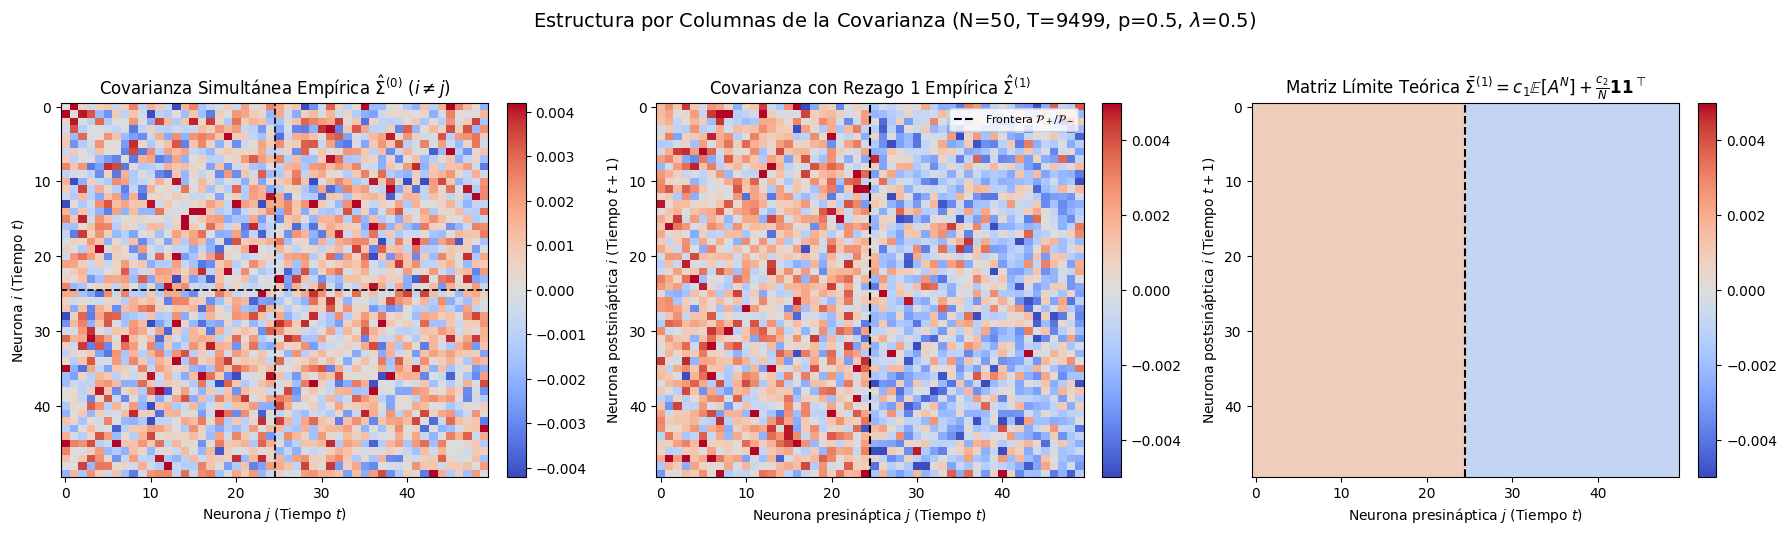

In [ ]:
Sigma0_hat = (Xo[:Tn] - m_hat).T @ (Xo[:Tn] - m_hat) / Tn

# Matriz asintótica teórica con rezago 1 (ecuación 21 de paper)
sigma_bar_ag = np.zeros(N)
sigma_bar_ag[P_plus_true] = sigma_plus_theo
sigma_bar_ag[P_minus_true] = sigma_minus_theo
Sigma1_bar_theo = np.outer(np.ones(N) / N, sigma_bar_ag)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

# Mapa de calor de matriz de covarianza 0-lagged (sin la diagonal principal para apreciar covarianzas cruzadas)
# Mide si neurona i y neurona j disparan en el mismo instante de tiempo t
Sigma0_offdiag = Sigma0_hat - np.diag(np.diag(Sigma0_hat))
#inicio IA
v0 = np.percentile(np.abs(Sigma0_offdiag), 98)
im0 = axes[0].imshow(Sigma0_offdiag, cmap='coolwarm', vmin=-v0, vmax=v0, aspect='auto')
axes[0].axvline(N // 2 - 0.5, color='black', linestyle='--', linewidth=1.2)
axes[0].axhline(N // 2 - 0.5, color='black', linestyle='--', linewidth=1.2)
axes[0].set_title(r'Covarianza Simultánea Empírica $\hat{\Sigma}^{(0)}$ ($i \neq j$)')
axes[0].set_xlabel('Neurona $j$ (Tiempo $t$)')
axes[0].set_ylabel('Neurona $i$ (Tiempo $t$)')
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

# Mapa de calor de matriz de covarianza 1-lagged
# mide cuanto afecta el disparo (o no disparo) de neurona j en tiempo t al disparo de
# neurona i en tiempo t+1
v1 = np.percentile(np.abs(Sigma1_hat), 98)
im1 = axes[1].imshow(Sigma1_hat, cmap='coolwarm', vmin=-v1, vmax=v1, aspect='auto')

axes[1].axvline(N // 2 - 0.5, color='black', linestyle='--', linewidth=1.5, label=r'Frontera $\mathcal{P}_+ / \mathcal{P}_-$')
axes[1].set_title(r'Covarianza con Rezago 1 Empírica $\hat{\Sigma}^{(1)}$')
axes[1].set_xlabel('Neurona presináptica $j$ (Tiempo $t$)')
axes[1].set_ylabel('Neurona postsináptica $i$ (Tiempo $t+1$)')
axes[1].legend(loc='upper right', fontsize=8)
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

# Mapa de calor de matriz de covarianza 1-lagged teórica
im2 = axes[2].imshow(Sigma1_bar_theo, cmap='coolwarm', vmin=-v1, vmax=v1, aspect='auto')
axes[2].axvline(N // 2 - 0.5, color='black', linestyle='--', linewidth=1.5)
axes[2].set_title(r'Matriz Límite Teórica $\bar{\Sigma}^{(1)} = c_1 \mathbb{E}[A^N] + \frac{c_2}{N}\mathbf{1}\mathbf{1}^\top$')
axes[2].set_xlabel('Neurona presináptica $j$ (Tiempo $t$)')
axes[2].set_ylabel('Neurona postsináptica $i$ (Tiempo $t+1$)')
plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)
#Fin IA
plt.suptitle(rf'Estructura por Columnas de la Covarianza (N={N}, T={Tn}, p={p}, $\lambda$={lmbda})', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

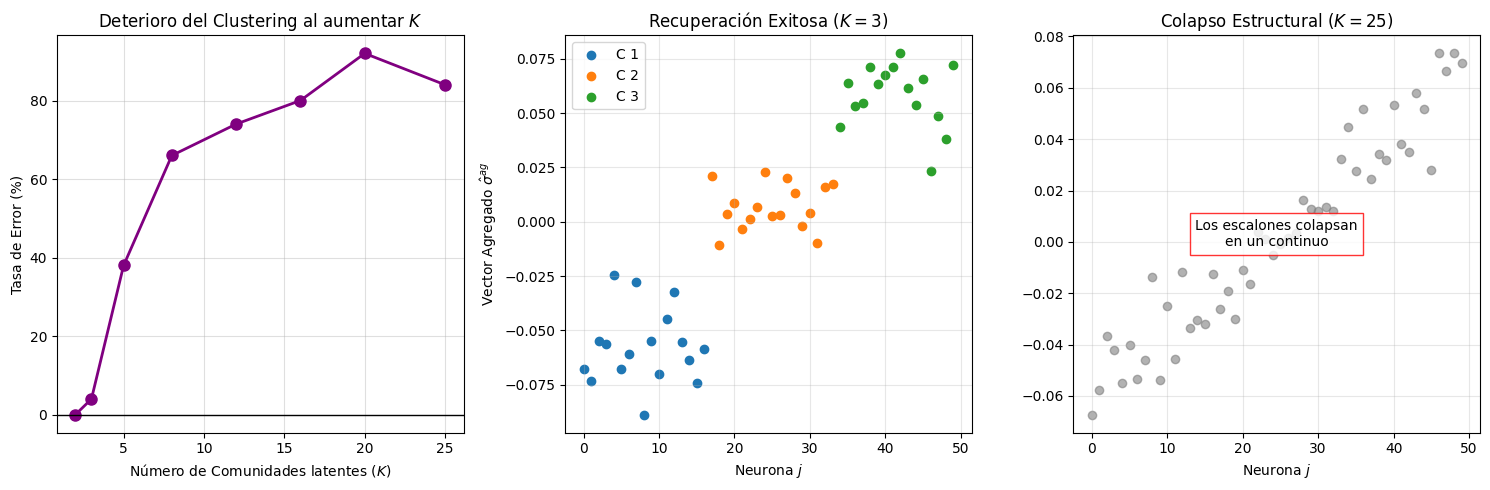

In [ ]:
#K means pero con K comunidades distintas, no 2 (hay diferencias entre neuronas activadoras e inhibidoras)
#esta parte del código fue mitad IA mitad no
def evaluar_limite_K(N=150, T=5000, p=0.5, mu=0.1, lmbda=0.3, K_valores=[2, 3, 5, 8, 12, 20]):

    errores = []
    rng = np.random.default_rng(123)

    for K in K_valores:

        # se simulan K comunidades
        etiquetas_reales = np.repeat(np.arange(K), np.ceil(N / K))[:N]
        pesos_comunidad = np.linspace(-1.0, 1.0, K)
        signos_nodos = pesos_comunidad[etiquetas_reales]

        theta = rng.binomial(1, p, size=(N, N))
        A_N = (theta * signos_nodos[None, :]) / N

        mask_inhib = signos_nodos < 0
        offset_inhib = (theta[:, mask_inhib] @ np.abs(signos_nodos[mask_inhib])) / N

        burn_in = 200
        X = np.zeros((T + burn_in + 1, N), dtype=int)
        X[0] = rng.binomial(1, 0.5, size=N)


        for t in range(T + burn_in):
            q_t = mu + (1.0 - lmbda) * (A_N @ X[t] + offset_inhib)
            q_t = np.clip(q_t, 0.01, 0.99)
            X[t + 1] = rng.binomial(1, q_t)


        Xo = X[burn_in:]
        m_hat = Xo[:T].mean(axis=0)
        Sigma1_hat = (Xo[1:T+1] - m_hat).T @ (Xo[:T] - m_hat) / T
        sigma_hat = Sigma1_hat.sum(axis=0)


        km = KMeans(n_clusters=K, n_init=15, random_state=42).fit(sigma_hat.reshape(-1, 1))

        orden_centroides = np.argsort(km.cluster_centers_.ravel())
        etiquetas_estimadas = np.argsort(orden_centroides)[km.labels_]

        tasa_error = np.mean(etiquetas_estimadas != etiquetas_reales)
        errores.append(tasa_error)


        if K == K_valores[1]:
            sig_k_bajo = sigma_hat.copy()
            real_k_bajo = etiquetas_reales.copy()
        if K == K_valores[-1]:
            sig_k_alto = sigma_hat.copy()
            real_k_alto = etiquetas_reales.copy()

    return K_valores, errores, sig_k_bajo, real_k_bajo, sig_k_alto, real_k_alto


K_lista = [2, 3, 5, 8, 12, 16, 20, 25]
K_vals, err_vals, sig_bajo, real_bajo, sig_alto, real_alto = evaluar_limite_K(N=50, T=10000, K_valores=K_lista)


fig = plt.figure(figsize=(15, 5))


ax1 = plt.subplot(1, 3, 1)
ax1.plot(K_vals, np.array(err_vals) * 100, marker='o', color='purple', linewidth=2, markersize=8)
ax1.set_title("Deterioro del Clustering al aumentar $K$")
ax1.set_xlabel("Número de Comunidades latentes ($K$)")
ax1.set_ylabel("Tasa de Error (%)")
ax1.axhline(0, color='black', linewidth=1)
ax1.grid(alpha=0.4)


ax2 = plt.subplot(1, 3, 2)
for c in range(3):
    mask = (real_bajo == c)
    ax2.scatter(np.where(mask)[0], sig_bajo[mask], label=f'C {c+1}')
ax2.set_title("Recuperación Exitosa ($K=3$)")
ax2.set_xlabel("Neurona $j$")
ax2.set_ylabel(r"Vector Agregado $\hat{\sigma}^{ag}$")
ax2.legend()
ax2.grid(alpha=0.3)

# K = 25
ax3 = plt.subplot(1, 3, 3)
K_max = K_lista[-1]
for c in range(K_max):
    mask = (real_alto == c)

    ax3.scatter(np.where(mask)[0], sig_alto[mask], color='gray', alpha=0.6)
ax3.set_title(f"Colapso Estructural ($K={K_max}$)")
ax3.set_xlabel("Neurona $j$")
ax3.grid(alpha=0.3)
ax3.text(0.5, 0.5, "Los escalones colapsan\nen un continuo",
         transform=ax3.transAxes, ha='center', va='center',
         bbox=dict(facecolor='white', alpha=0.8, edgecolor='red'), fontsize=10)

plt.tight_layout()
plt.show()